![Torch-Tensorrt](https://developer-blogs.nvidia.com/wp-content/uploads/2021/12/pytorch-torch-tensorrt.png)

[Torch-TensorRT](http://https://developer.nvidia.com/blog/accelerating-inference-up-to-6x-faster-in-pytorch-with-torch-tensorrt/) is an integration for PyTorch that leverages inference optimizations of TensorRT on NVIDIA GPUs.  This notebook demonstrates how to install the necessary libraries for torch_tensorrt and how to convert models for speedup.

Plenty of great torch_tensorrt example notebooks reside [here](https://github.com/pytorch/TensorRT/tree/master/notebooks).  This notebook was adapted from the efn notebook in that folder.

# Install Dependencies

In [1]:
!dpkg -l | grep nvinfer

ii  libnvinfer-plugin8                8.4.1-1+cuda11.6                  amd64        TensorRT plugin libraries
ii  libnvinfer8                       8.4.1-1+cuda11.6                  amd64        TensorRT runtime libraries
ii  python3-libnvinfer                8.4.1-1+cuda11.6                  amd64        Python 3 bindings for TensorRT


In [2]:
#upgrade pytorch to 1.12
!pip install /kaggle/input/pytorch112-cu113/{torch-1.12.1+cu113-cp37-cp37m-linux_x86_64.whl,torchvision-0.13.1+cu113-cp37-cp37m-linux_x86_64.whl}
#install nvidia-pyindex
!pip install /kaggle/input/torch-tensorrt-pkg/nvidia_pyindex-1.0.9-py3-none-any.whl
#install nvidia_tensorrt
!mkdir -p /tmp/pip/cache/
!cp /kaggle/input/torch-tensorrt-pkg/nvidia-cublas-cu11-2022.4.8.xyz /tmp/pip/cache/nvidia-cublas-cu11-2022.4.8.tar.gz
!cp /kaggle/input/torch-tensorrt-pkg/nvidia-cuda-runtime-cu11-2022.4.25.xyz /tmp/pip/cache/nvidia-cuda-runtime-cu11-2022.4.25.tar.gz
!cp /kaggle/input/torch-tensorrt-pkg/nvidia-cudnn-cu11-2022.5.19.xyz /tmp/pip/cache/nvidia-cudnn-cu11-2022.5.19.tar.gz
!cp /kaggle/input/torch-tensorrt-pkg/nvidia_cublas_cu117-11.10.1.25-py3-none-manylinux1_x86_64.whl /tmp/pip/cache/
!cp /kaggle/input/torch-tensorrt-pkg/nvidia_cuda_runtime_cu117-11.7.60-py3-none-manylinux1_x86_64.whl /tmp/pip/cache/
!cp /kaggle/input/torch-tensorrt-pkg/nvidia_cudnn_cu116-8.4.0.27-py3-none-manylinux1_x86_64.whl /tmp/pip/cache/
!cp /kaggle/input/torch-tensorrt-pkg/nvidia_tensorrt-8.4.3.1-cp37-none-linux_x86_64.whl /tmp/pip/cache/
!pip install --no-index --find-links /tmp/pip/cache/ nvidia_tensorrt
#install torch_tensorrt
!pip install /kaggle/input/torch-tensorrt-pkg/torch_tensorrt-1.2.0-cp37-cp37m-linux_x86_64.whl


Processing /kaggle/input/pytorch112-cu113/torch-1.12.1+cu113-cp37-cp37m-linux_x86_64.whl
Processing /kaggle/input/pytorch112-cu113/torchvision-0.13.1+cu113-cp37-cp37m-linux_x86_64.whl
  Attempting uninstall: torch
    Found existing installation: torch 1.11.0
    Uninstalling torch-1.11.0:
      Successfully uninstalled torch-1.11.0
  Attempting uninstall: torchvision
    Found existing installation: torchvision 0.12.0
    Uninstalling torchvision-0.12.0:
      Successfully uninstalled torchvision-0.12.0
Processing /kaggle/input/torch-tensorrt-pkg/nvidia_pyindex-1.0.9-py3-none-any.whl
Looking in links: /tmp/pip/cache/
Processing /tmp/pip/cache/nvidia_tensorrt-8.4.3.1-cp37-none-linux_x86_64.whl
Processing /tmp/pip/cache/nvidia-cublas-cu11-2022.4.8.tar.gz
  Preparing metadata (setup.py) ... - done
Processing /tmp/pip/cache/nvidia-cuda-runtime-cu11-2022.4.25.tar.gz
  Preparing metadata (setup.py) ... - done
Processing /tmp/pip/cache/nvidia-cudnn-cu11-2022.5.19.tar.gz
  Preparing metad

In [3]:
!pip install --upgrade pip
!pip install --upgrade sphinx-glpi-theme

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 9.6 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 22.1.2
    Uninstalling pip-22.1.2:
      Successfully uninstalled pip-22.1.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 14.1 MB/s eta 0:00:00
DEPRECATION: pytorch-lightning 1.7.7 has a non-standard dependency specifier torch>=1.9.*. pip 24.1 will enforce this behaviour change. A possible replacement is to upgrade to a newer version of pytorch-lightning or contact the author to suggest that they release a version with a conforming dependency specifiers. Discussion can be found at https://github.com/pypa/pip/issues/12063
DEPRECATION: torch-tensorrt 1.2.0 has a non-standard dependency specifier torch<1.13.0,>=1.12.0+cu116. pip 24.1 will enforce this behaviour change. A possible replacement is to upgrade to a newer version of torch-tensorrt or contact the author to suggest that they release a version with a conforming dependency specifi

In [4]:
!pip install --no-cache-dir --index-url https://pypi.nvidia.com pytorch-quantization


Looking in indexes: https://pypi.nvidia.com
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.1/54.1 kB 4.3 MB/s eta 0:00:00
DEPRECATION: pytorch-lightning 1.7.7 has a non-standard dependency specifier torch>=1.9.*. pip 24.1 will enforce this behaviour change. A possible replacement is to upgrade to a newer version of pytorch-lightning or contact the author to suggest that they release a version with a conforming dependency specifiers. Discussion can be found at https://github.com/pypa/pip/issues/12063
DEPRECATION: torch-tensorrt 1.2.0 has a non-standard dependency specifier torch<1.13.0,>=1.12.0+cu116. pip 24.1 will enforce this behaviour change. A possible replacement is to upgrade to a newer version of torch-tensorrt or contact the author to suggest that they release a version with a conforming dependency specifiers. Discussion can be found at https://github.com/pypa/pip/issues/12063


# Import libraries and benchmarking functions

In [5]:
import torch
import torchvision
import tensorrt
import torch_tensorrt
import sys
sys.path.append('../input/timm-pytorch-image-models/pytorch-image-models-master')
import timm

!mkdir -p /root/.cache/torch/hub/checkpoints/
!cp /kaggle/input/few-imagenet-examples/efficientnet_b0_ra-3dd342df.pth /root/.cache/torch/hub/checkpoints/
!cp /kaggle/input/few-imagenet-examples/efficientnet_b2_ra-bcdf34b7.pth /root/.cache/torch/hub/checkpoints/

import time
import numpy as np
import torch.backends.cudnn as cudnn
from timm.data import resolve_data_config
from timm.data.transforms_factory import create_transform
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import json

# loading labels
with open("/kaggle/input/few-imagenet-examples/data/imagenet_class_index.json") as json_file: 
    d = json.load(json_file)
  


In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import torch_tensorrt
from torch.utils.tensorboard import SummaryWriter

import pytorch_quantization
from pytorch_quantization import nn as quant_nn
from pytorch_quantization import quant_modules
from pytorch_quantization.tensor_quant import QuantDescriptor
from pytorch_quantization import calib
from tqdm import tqdm

print(pytorch_quantization.__version__)

import os
import sys
#sys.path.insert(0, "../examples/int8/training/vgg16")
#from vgg16 import vgg16

2.1.3


In [7]:
!nvidia-smi
!pip install ipywidgets --trusted-host pypi.org --trusted-host pypi.python.org --trusted-host=files.pythonhosted.org

Mon Feb 19 05:07:04 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.129.03             Driver Version: 535.129.03   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla T4                       Off | 00000000:00:04.0 Off |                    0 |
| N/A   41C    P8               9W /  70W |      3MiB / 15360MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [8]:
# torch.hub._validate_not_a_forked_repo=lambda a,b,c: True
#model = torch.hub.load('pytorch/vision:v0.10.0', 'resnet18', pretrained=True)
#resnet50_model = torch.hub.load('pytorch/vision:v0.10.0', 'resnet50', pretrained=True)


In [9]:
IMG_SIZE=1024
N_CHANNELS=3
BATCH_SIZE=8

In [10]:
#create model
# efn_b2_model = timm.create_model('efficientnet_b2',pretrained=True)
# model = efn_b2_model.eval().to("cuda")
resnet50_model = timm.create_model('resnet50',pretrained=True)
model = resnet50_model.eval().to("cuda")

Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-rsb-weights/resnet50_a1_0-14fe96d1.pth" to /root/.cache/torch/hub/checkpoints/resnet50_a1_0-14fe96d1.pth


In [11]:
cudnn.benchmark = True

def efficientnet_preprocess():
    config = resolve_data_config({}, model=model)
    transform = create_transform(**config)
    return transform

# decode the results into ([predicted class, description], probability)
def predict(img_path, model, dtype):
    img = Image.open(img_path)
    preprocess = efficientnet_preprocess()
    input_tensor = preprocess(img)
    resize_tform = transforms.Compose([transforms.Resize((IMG_SIZE))])
    input_tensor = resize_tform(input_tensor)
    input_batch = input_tensor.unsqueeze(0) # create a mini-batch as expected by the model
    if dtype=='fp16':
        input_batch = input_batch.half()
    
    # move the input and model to GPU for speed if available
    if torch.cuda.is_available():
        input_batch = input_batch.to('cuda')
        model.to('cuda')

    with torch.no_grad():
        output = model(input_batch)
        # Tensor of shape 1000, with confidence scores over Imagenet's 1000 classes
        sm_output = torch.nn.functional.softmax(output[0], dim=0)
        
    ind = torch.argmax(sm_output)
    return d[str(ind.item())], sm_output[ind] #([predicted class, description], probability)

def benchmark(model, input_shape=(BATCH_SIZE, N_CHANNELS, IMG_SIZE, IMG_SIZE), dtype='fp32', nwarmup=50, nruns=10000):
    input_data = torch.randn(input_shape)
    input_data = input_data.to("cuda")
    if dtype=='fp16':
        input_data = input_data.half()
        
    print("Warm up ...")
    with torch.no_grad():
        for _ in range(nwarmup):
            features = model(input_data)
    torch.cuda.synchronize()
    print("Start timing ...")
    timings = []
    with torch.no_grad():
        for i in range(1, nruns+1):
            start_time = time.time()
            features = model(input_data)
            torch.cuda.synchronize()
            end_time = time.time()
            timings.append(end_time - start_time)
            if i%10==0:
                print('Iteration %d/%d, avg batch time %.2f ms'%(i, nruns, np.mean(timings)*1000))

    print("Input shape:", input_data.size())
    print("Output features size:", features.size())
    print('Average throughput: %.2f images/second'%(input_shape[0]/np.mean(timings)))

# Run regular torch model (fp32), no torch_tensorrt

In [12]:
# Model benchmark in Pytorch fp32 without Torch-TensorRT
benchmark(model, input_shape=(BATCH_SIZE, N_CHANNELS, IMG_SIZE, IMG_SIZE), nruns=100)

Warm up ...
Start timing ...
Iteration 10/100, avg batch time 435.96 ms
Iteration 20/100, avg batch time 436.98 ms
Iteration 30/100, avg batch time 438.02 ms
Iteration 40/100, avg batch time 439.11 ms
Iteration 50/100, avg batch time 440.09 ms
Iteration 60/100, avg batch time 441.11 ms
Iteration 70/100, avg batch time 442.13 ms
Iteration 80/100, avg batch time 443.18 ms
Iteration 90/100, avg batch time 444.28 ms
Iteration 100/100, avg batch time 445.42 ms
Input shape: torch.Size([8, 3, 1024, 1024])
Output features size: torch.Size([8, 1000])
Average throughput: 17.96 images/second


# Compile and infer torch_tensorrt model (fp32)

In [13]:
trt_model_fp32 = torch_tensorrt.compile(model, inputs = [torch_tensorrt.Input(min_shape=[1, N_CHANNELS, IMG_SIZE, IMG_SIZE],opt_shape=[BATCH_SIZE, N_CHANNELS, IMG_SIZE, IMG_SIZE],max_shape=[BATCH_SIZE, N_CHANNELS, IMG_SIZE, IMG_SIZE],dtype=torch.float32)],
    enabled_precisions = torch.float32, # Run with FP32
    workspace_size = 1 << 32
)

In [14]:
# Obtain the average time taken by a batch of input
benchmark(trt_model_fp32, input_shape=(BATCH_SIZE, N_CHANNELS, IMG_SIZE, IMG_SIZE), nruns=100)

Warm up ...
Start timing ...
Iteration 10/100, avg batch time 319.92 ms
Iteration 20/100, avg batch time 319.28 ms
Iteration 30/100, avg batch time 319.15 ms
Iteration 40/100, avg batch time 318.96 ms
Iteration 50/100, avg batch time 318.75 ms
Iteration 60/100, avg batch time 318.62 ms
Iteration 70/100, avg batch time 318.52 ms
Iteration 80/100, avg batch time 318.39 ms
Iteration 90/100, avg batch time 318.36 ms
Iteration 100/100, avg batch time 318.42 ms
Input shape: torch.Size([8, 3, 1024, 1024])
Output features size: torch.Size([8, 1000])
Average throughput: 25.12 images/second


# Matched results between pytorch and torch_tensorrt models.

/kaggle/input/few-imagenet-examples/data/img0.JPG - Predicted: ['n02120079', 'Arctic_fox'], Probablility: 0.010187271051108837
/kaggle/input/few-imagenet-examples/data/img1.JPG - Predicted: ['n01930112', 'nematode'], Probablility: 0.00966248195618391
/kaggle/input/few-imagenet-examples/data/img2.JPG - Predicted: ['n02481823', 'chimpanzee'], Probablility: 0.03749285638332367
/kaggle/input/few-imagenet-examples/data/img3.JPG - Predicted: ['n01749939', 'green_mamba'], Probablility: 0.02336481586098671


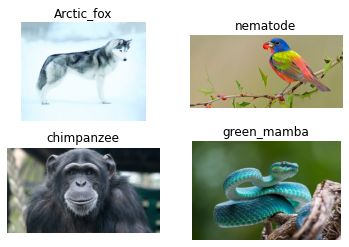

In [15]:
#FP32 prediction

for i in range(4):
    img_path = '/kaggle/input/few-imagenet-examples/data/img%d.JPG'%i
    img = Image.open(img_path)
    
    pred, prob = predict(img_path, model, dtype='fp32')
    print('{} - Predicted: {}, Probablility: {}'.format(img_path, pred, prob))

    plt.subplot(2,2,i+1)
    plt.imshow(img);
    plt.axis('off');
    plt.title(pred[1])

/kaggle/input/few-imagenet-examples/data/img0.JPG - Predicted: ['n02120079', 'Arctic_fox'], Probablility: 0.010187266394495964
/kaggle/input/few-imagenet-examples/data/img1.JPG - Predicted: ['n01930112', 'nematode'], Probablility: 0.009662494994699955
/kaggle/input/few-imagenet-examples/data/img2.JPG - Predicted: ['n02481823', 'chimpanzee'], Probablility: 0.03749285638332367
/kaggle/input/few-imagenet-examples/data/img3.JPG - Predicted: ['n01749939', 'green_mamba'], Probablility: 0.02336478978395462


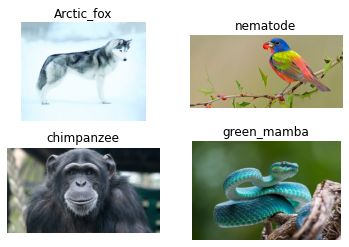

In [16]:
#FP32 prediction torch_tensorrt
for i in range(4):
    img_path = '/kaggle/input/few-imagenet-examples/data/img%d.JPG'%i
    img = Image.open(img_path)
    
    pred, prob = predict(img_path, trt_model_fp32, dtype='fp32')
    print('{} - Predicted: {}, Probablility: {}'.format(img_path, pred, prob))

    plt.subplot(2,2,i+1)
    plt.imshow(img);
    plt.axis('off');
    plt.title(pred[1])

# Run regular torch model (fp16), no torch_tensorrt

In [17]:
# Model benchmark in Pytorch fp32 without Torch-TensorRT
benchmark(model.half().eval(), input_shape=(BATCH_SIZE, N_CHANNELS, IMG_SIZE, IMG_SIZE), dtype='fp16', nruns=100)

Warm up ...
Start timing ...
Iteration 10/100, avg batch time 189.44 ms
Iteration 20/100, avg batch time 189.61 ms
Iteration 30/100, avg batch time 189.82 ms
Iteration 40/100, avg batch time 189.97 ms
Iteration 50/100, avg batch time 190.09 ms
Iteration 60/100, avg batch time 190.25 ms
Iteration 70/100, avg batch time 190.34 ms
Iteration 80/100, avg batch time 190.47 ms
Iteration 90/100, avg batch time 190.54 ms
Iteration 100/100, avg batch time 190.60 ms
Input shape: torch.Size([8, 3, 1024, 1024])
Output features size: torch.Size([8, 1000])
Average throughput: 41.97 images/second


# Compile and infer torch_tensorrt model (fp16)

In [18]:
trt_model_fp16 = torch_tensorrt.compile(model.half().eval(), inputs = [torch_tensorrt.Input(min_shape=[1, N_CHANNELS, IMG_SIZE, IMG_SIZE],opt_shape=[BATCH_SIZE, N_CHANNELS, IMG_SIZE, IMG_SIZE],max_shape=[BATCH_SIZE, N_CHANNELS, IMG_SIZE, IMG_SIZE],dtype=torch.half)],
    enabled_precisions = {torch.half}, # Run with FP16
    workspace_size = 1 << 32
)

ERROR: [Torch-TensorRT TorchScript Conversion Context] - 2: [virtualMemoryBuffer.cpp::resizePhysical::144] Error Code 2: OutOfMemory (no further information)
ERROR: [Torch-TensorRT TorchScript Conversion Context] - 2: [virtualMemoryBuffer.cpp::resizePhysical::144] Error Code 2: OutOfMemory (no further information)
ERROR: [Torch-TensorRT TorchScript Conversion Context] - 2: [virtualMemoryBuffer.cpp::resizePhysical::144] Error Code 2: OutOfMemory (no further information)
ERROR: [Torch-TensorRT TorchScript Conversion Context] - 2: [virtualMemoryBuffer.cpp::resizePhysical::144] Error Code 2: OutOfMemory (no further information)
ERROR: [Torch-TensorRT TorchScript Conversion Context] - 2: [virtualMemoryBuffer.cpp::resizePhysical::144] Error Code 2: OutOfMemory (no further information)
ERROR: [Torch-TensorRT TorchScript Conversion Context] - 2: [virtualMemoryBuffer.cpp::resizePhysical::144] Error Code 2: OutOfMemory (no further information)
ERROR: [Torch-TensorRT TorchScript Conversion Contex

In [19]:
# Obtain the average time taken by a batch of input
benchmark(trt_model_fp16, input_shape=(BATCH_SIZE, N_CHANNELS, IMG_SIZE, IMG_SIZE), dtype='fp16', nruns=100)

Warm up ...
Start timing ...
Iteration 10/100, avg batch time 79.39 ms
Iteration 20/100, avg batch time 80.32 ms
Iteration 30/100, avg batch time 80.33 ms
Iteration 40/100, avg batch time 80.61 ms
Iteration 50/100, avg batch time 80.80 ms
Iteration 60/100, avg batch time 80.86 ms
Iteration 70/100, avg batch time 80.84 ms
Iteration 80/100, avg batch time 80.88 ms
Iteration 90/100, avg batch time 80.91 ms
Iteration 100/100, avg batch time 80.98 ms
Input shape: torch.Size([8, 3, 1024, 1024])
Output features size: torch.Size([8, 1000])
Average throughput: 98.78 images/second


# Matched results between torch and torch_tensorrt models (FP16)

/kaggle/input/few-imagenet-examples/data/img0.JPG - Predicted: ['n02120079', 'Arctic_fox'], Probablility: 0.01018524169921875
/kaggle/input/few-imagenet-examples/data/img1.JPG - Predicted: ['n01930112', 'nematode'], Probablility: 0.009613037109375
/kaggle/input/few-imagenet-examples/data/img2.JPG - Predicted: ['n02481823', 'chimpanzee'], Probablility: 0.03729248046875
/kaggle/input/few-imagenet-examples/data/img3.JPG - Predicted: ['n01749939', 'green_mamba'], Probablility: 0.0230712890625


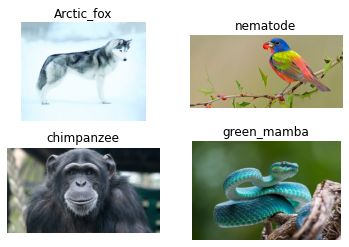

In [20]:
for i in range(4):
    img_path = '/kaggle/input/few-imagenet-examples/data/img%d.JPG'%i
    img = Image.open(img_path)
    
    pred, prob = predict(img_path, model.half().eval(), dtype='fp16')
    print('{} - Predicted: {}, Probablility: {}'.format(img_path, pred, prob))

    plt.subplot(2,2,i+1)
    plt.imshow(img);
    plt.axis('off');
    plt.title(pred[1])

/kaggle/input/few-imagenet-examples/data/img0.JPG - Predicted: ['n02120079', 'Arctic_fox'], Probablility: 0.010147877968847752
/kaggle/input/few-imagenet-examples/data/img1.JPG - Predicted: ['n01930112', 'nematode'], Probablility: 0.0096572982147336
/kaggle/input/few-imagenet-examples/data/img2.JPG - Predicted: ['n02481823', 'chimpanzee'], Probablility: 0.03814388066530228
/kaggle/input/few-imagenet-examples/data/img3.JPG - Predicted: ['n01749939', 'green_mamba'], Probablility: 0.022996556013822556


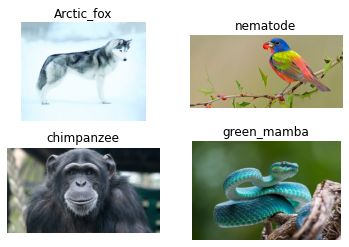

In [21]:
for i in range(4):
    img_path = '/kaggle/input/few-imagenet-examples/data/img%d.JPG'%i
    img = Image.open(img_path)
    
    pred, prob = predict(img_path, trt_model_fp16, dtype='fp16')
    print('{} - Predicted: {}, Probablility: {}'.format(img_path, pred, prob))

    plt.subplot(2,2,i+1)
    plt.imshow(img);
    plt.axis('off');
    plt.title(pred[1])

# Save and load torch_tensorrt model for inference.

In [22]:
#save and reload trt model for inference:
torch.jit.save(trt_model_fp16, f"/kaggle/working/trt_model_fp16.ts")

print('Loading TensorRT model ...')
model_loaded = torch.jit.load(f"/kaggle/working/trt_model_fp16.ts")

Loading TensorRT model ...


/kaggle/input/few-imagenet-examples/data/img0.JPG - Predicted: ['n02120079', 'Arctic_fox'], Probablility: 0.010147877968847752
/kaggle/input/few-imagenet-examples/data/img1.JPG - Predicted: ['n01930112', 'nematode'], Probablility: 0.0096572982147336
/kaggle/input/few-imagenet-examples/data/img2.JPG - Predicted: ['n02481823', 'chimpanzee'], Probablility: 0.03814388066530228
/kaggle/input/few-imagenet-examples/data/img3.JPG - Predicted: ['n01749939', 'green_mamba'], Probablility: 0.022996556013822556


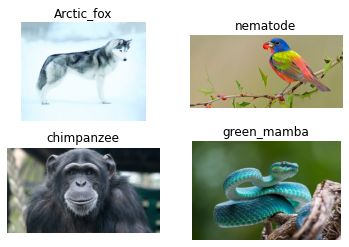

In [23]:
for i in range(4):
    img_path = '/kaggle/input/few-imagenet-examples/data/img%d.JPG'%i
    img = Image.open(img_path)
    
    pred, prob = predict(img_path, model_loaded, dtype='fp16')
    print('{} - Predicted: {}, Probablility: {}'.format(img_path, pred, prob))

    plt.subplot(2,2,i+1)
    plt.imshow(img);
    plt.axis('off');
    plt.title(pred[1])